# Flowchart Simulasi Pengereman Kendaraan (Fisika Komputasi)

Notebook ini memuat diagram alir (*flowchart*) dan implementasi algoritma sistem pengereman kendaraan berdasarkan prinsip kinematika dan dinamika gerak lurus berubah beraturan (GLBB).

---

## 1. Visualisasi Diagram Alir (Flowchart)

Diagram alir di bawah ini disajikan secara visual (vektor SVG langsung) dan dalam bentuk kode sumber Mermaid yang sudah diperbaiki sintaksisnya:

<div align="center">
  
</div>

<br/>

<details open>
<summary><b>Kode Sumber Mermaid (Syntax Valid)</b></summary>

```mermaid
flowchart TD
    A(["Terminal: Mulai"]) --> B["Tetapkan konstanta<br/>g = 9,8 m/s²"]
    B --> C[/"Input:<br/>Kecepatan awal v₀ dalam m/s<br/>Koefisien gesek μ<br/>Jarak ke dinding d dalam meter"/]
    C --> D{"Apakah v₀ ≥ 0,<br/>μ > 0, dan d > 0?"}
    D -->|Tidak| E["Periksa input kembali"]
    E --> C
    D -->|Ya| F["Konversi kecepatan"]
    F --> G["Hitung besar perlambatan<br/>a = μ × g"]
    G --> H["Hitung jarak pengereman<br/>s = v₀² / 2a"]
    H --> I{"Apakah s ≤ d?"}
    I -->|Ya| J["Kecepatan akhir vₐ = 0<br/>Hitung sisa jarak d - s"]
    J --> K[/"Output:<br/>Berhenti tanpa benturan<br/>Jarak pengereman s<br/>Sisa jarak d - s"/]
    I -->|Tidak| L["Hitung kecepatan benturan<br/>v_b = √(v₀² - 2ad)"]
    L --> M[/"Output:<br/>Terjadi benturan<br/>Jarak pengereman yang dibutuhkan s<br/>Kecepatan benturan v_b"/]
    K --> N(["Terminate: Selesai"])
    M --> N

    classDef terminal fill:#dbeafe,stroke:#1d4ed8,stroke-width:2px
    classDef process fill:#fef3c7,stroke:#d97706,stroke-width:2px
    classDef io fill:#dcfce7,stroke:#16a34a,stroke-width:2px
    classDef decision fill:#fce7f3,stroke:#db2777,stroke-width:2px
    classDef error fill:#fee2e2,stroke:#dc2626,stroke-width:2px
    class A,N terminal
    class B,F,G,H,J,L process
    class C,K,M io
    class D,I decision
    class E error
```

</details>

---

## 2. Keterangan Simbol & Alur Logika

- **Terminal (Kapsul Biru):** Titik mulai (`A`) dan selesai (`N`).
- **Input / Output (Jajar Genjang Hijau):** Membaca parameter awal ($v_0, \mu, d$) dan menampilkan hasil perhitungan.
- **Keputusan / Decision (Belah Ketupat Merah Muda):**
  - Validasi parameter fisis ($v_0 \ge 0, \mu > 0, d > 0$).
  - Evaluasi jarak henti terhadap jarak rintangan ($s \le d$).
- **Proses / Perhitungan (Persegi Kuning):** Menghitung perlambatan $a$, jarak henti $s$, sisa jarak $d - s$, dan kecepatan benturan $v_b$.
- **Error Handling (Persegi Merah):** Mengembalikan alur ke input apabila parameter tidak valid.

---

## 3. Formulasi Matematis

1. **Perlambatan oleh gaya gesek ($a$):**
   $$a = \mu \cdot g$$
2. **Jarak pengereman sampai berhenti ($s$):**
   $$s = \frac{v_0^2}{2a} = \frac{v_0^2}{2\mu g}$$
3. **Kondisi 1: Berhenti Tanpa Benturan ($s \le d$)**
   - Kecepatan akhir: $v_a = 0$
   - Sisa jarak aman: $\Delta d = d - s$
4. **Kondisi 2: Terjadi Benturan ($s > d$)**
   - Kecepatan saat membentur dinding ($v_b$):
     $$v_b = \sqrt{v_0^2 - 2ad}$$



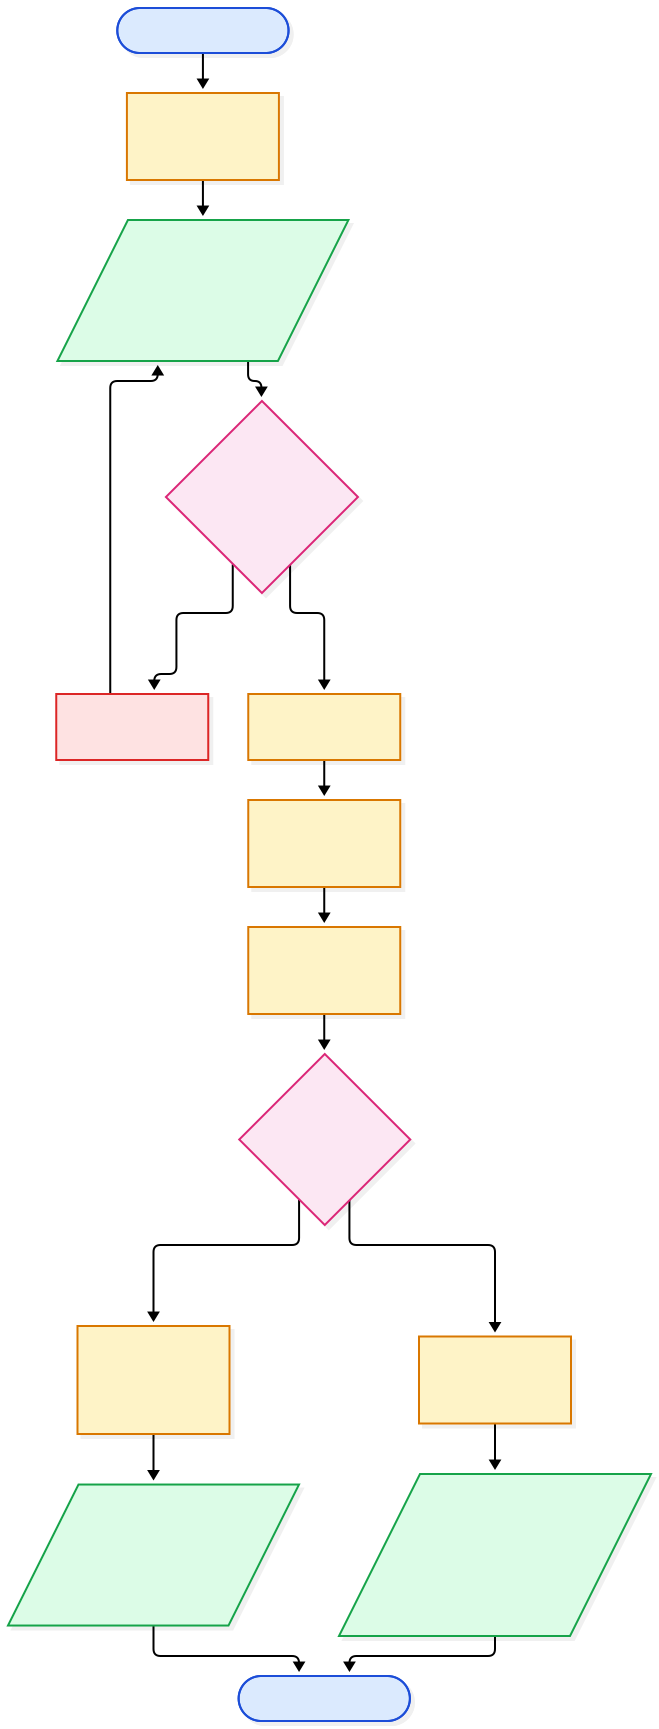

In [1]:
# Tampilkan diagram vektor langsung melalui output IPython
from IPython.display import SVG, display

display(SVG(filename='flowchart.svg'))



---

## 4. Eksekusi Interaktif Algoritma Flowchart (Python)

Berikut adalah implementasi Python yang menjalankan algoritma diagram alir di atas secara langsung:



In [2]:
import math

def simulasi_pengereman(v0_kmh: float, mu: float, d: float, g: float = 9.8):
    """
    Simulasi pengereman kendaraan sesuai flowchart.
    """
    # 1. Validasi Input
    if v0_kmh < 0 or mu <= 0 or d <= 0:
        return {"status": "ERROR", "pesan": "Input tidak valid! Pastikan v0 >= 0, mu > 0, dan d > 0."}
    
    # 2. Konversi Kecepatan (km/jam -> m/s)
    v0 = v0_kmh / 3.6
    
    # 3. Hitung Perlambatan (a = mu * g)
    a = mu * g
    
    # 4. Hitung Jarak Pengereman (s = v0^2 / 2a)
    s = (v0 ** 2) / (2 * a)
    
    # 5. Percabangan Keputusan: Apakah s <= d?
    if s <= d:
        sisa_jarak = d - s
        return {
            "status": "AMAN",
            "kondisi": "Berhenti tanpa benturan",
            "v0_ms": round(v0, 2),
            "perlambatan_a": round(a, 2),
            "jarak_henti_s": round(s, 2),
            "sisa_jarak": round(sisa_jarak, 2),
            "kecepatan_akhir": 0.0
        }
    else:
        v_b = math.sqrt(max(0.0, v0 ** 2 - 2 * a * d))
        v_b_kmh = v_b * 3.6
        return {
            "status": "TABRAKAN",
            "kondisi": "Terjadi benturan dinding!",
            "v0_ms": round(v0, 2),
            "perlambatan_a": round(a, 2),
            "jarak_butuh_s": round(s, 2),
            "kecepatan_benturan_ms": round(v_b, 2),
            "kecepatan_benturan_kmh": round(v_b_kmh, 2)
        }

# Uji Coba Kasus 1: Sesuai default project.js (v0 = 60 km/jam, mu = 0.60, d = 35 m)
hasil_1 = simulasi_pengereman(v0_kmh=60, mu=0.60, d=35)
print("=== KASUS 1: Parameter Default project.js ===")
for k, v in hasil_1.items():
    print(f"  {k}: {v}")

# Uji Coba Kasus 2: Kecepatan Tinggi / Jalan Basah (v0 = 100 km/jam, mu = 0.30, d = 35 m)
hasil_2 = simulasi_pengereman(v0_kmh=100, mu=0.30, d=35)
print("\n=== KASUS 2: Kecepatan Tinggi & Jalan Basah ===")
for k, v in hasil_2.items():
    print(f"  {k}: {v}")



=== KASUS 1: Parameter Default project.js ===
  status: AMAN
  kondisi: Berhenti tanpa benturan
  v0_ms: 16.67
  perlambatan_a: 5.88
  jarak_henti_s: 23.62
  sisa_jarak: 11.38
  kecepatan_akhir: 0.0

=== KASUS 2: Kecepatan Tinggi & Jalan Basah ===
  status: TABRAKAN
  kondisi: Terjadi benturan dinding!
  v0_ms: 27.78
  perlambatan_a: 2.94
  jarak_butuh_s: 131.23
  kecepatan_benturan_ms: 23.79
  kecepatan_benturan_kmh: 85.63
